# Week 8: Errors in regression — can we trust the coefficient, and can we trust its SE?

Two questions for every regression today:

- **A. Coefficient:** is it centered on the effect we intend?
- **B. Reported SE:** does it match how much the coefficient really moves from sample to sample?

| Part | Topic | Time | Question it answers |
|---|---|---:|---|
| 1 | Baseline: what an SE estimates | 5 min | B, when everything is fine |
| 2 | Omitted confounder: rain, flyers, and coffee | 8 min | A |
| 3 | Heteroskedasticity: right center, wrong SE | 13 min | B |
| 4 | Errors correlated across observations | 4 min | B |

**One yardstick throughout:** in a simulation we can rerun the study many times.

- **Empirical SD** of the coefficient across reruns = the real sampling variability
- **Mean reported SE** = what `statsmodels` tells us from one dataset
- **Ratio** = mean reported SE ÷ empirical SD → about 1 means the SE is honest; below 1 = overconfident

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.precision", 5)
BLUE, ORANGE, GREY = "#1B5AA6", "#D9822B", "#999999"


def repeat_regression(make_data, n_trials=500, seed=1):
    """Rerun the study n_trials times: draw data, fit OLS with an intercept,
    keep X's coefficient and its reported SE."""
    np.random.seed(seed)
    rows = []
    for _ in range(n_trials):
        Y, regressors = make_data()
        results = sm.OLS(Y, sm.add_constant(regressors)).fit()
        rows.append({"beta_hat": results.params["X"], "ols_se": results.bse["X"]})
    return pd.DataFrame(rows)


def summarize(sims, true_beta=2):
    """One row: true coefficient, mean estimate, empirical SD, mean reported SE, ratio."""
    out = {
        "true beta": true_beta,
        "mean beta_hat": sims["beta_hat"].mean(),
        "empirical SD": sims["beta_hat"].std(),
        "mean OLS SE": sims["ols_se"].mean(),
    }
    out["ratio"] = out["mean OLS SE"] / out["empirical SD"]   # about 1 = honest SE
    return pd.Series(out)


def plot_se_ratio(table, title):
    """Reported SE ÷ empirical SD per scenario, on a log scale: 1 = honest,
    left of 1 = SE too small (overconfident), right of 1 = SE too large."""
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.7 * len(table)))
    y = np.arange(len(table))[::-1]
    ax.axvline(1, color="black", lw=1.5)
    ax.scatter(table["ratio"], y, s=110, color=ORANGE, marker="D", zorder=3)
    ax.set_xscale("log")
    ax.set_xlim(0.2, 5)
    ax.set_xticks([0.25, 0.5, 1, 2, 4])
    ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"])
    ax.set_yticks(y)
    ax.set_yticklabels(table.index)
    ax.set_ylim(-0.6, len(table) - 0.4)
    ax.text(0.21, len(table) - 0.5, "← SE too small", color=GREY, va="center")
    ax.text(4.8, len(table) - 0.5, "SE too large →", color=GREY, va="center", ha="right")
    ax.set_xlabel("mean reported SE ÷ empirical SD  (log scale)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    plt.show()


def draw_dag(edges, pos, title, figsize=(5.5, 2.8), red=()):
    """Draw one causal diagram. Nodes in `red` are left out of the model."""
    fig, ax = plt.subplots(figsize=figsize)
    boxes = {}
    for node, (x, y) in pos.items():
        boxes[node] = ax.text(x, y, node, ha="center", va="center", fontsize=10,
                              bbox=dict(boxstyle="round,pad=0.4", ec="black", lw=1,
                                        fc="#FFE0E0" if node in red else "#D9EAF7"))
    for u, v in edges:
        ax.annotate("", xy=pos[v], xytext=pos[u],
                    arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.8, mutation_scale=18,
                                    patchA=boxes[u].get_bbox_patch(), patchB=boxes[v].get_bbox_patch(),
                                    shrinkA=2, shrinkB=2))
    xs, ys = zip(*pos.values())
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_title(title, fontsize=11)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

---
## Part 1: Baseline — what does a standard error estimate? (5 min)

- Simplest case: $Y = 2X + \varepsilon$
- $X$ and $\varepsilon$ independent; $\varepsilon \sim \mathcal{N}(0,\, 5^2)$: mean 0, constant spread → nothing is wrong

**Discussion:** a regression reports SE = 0.01 for X. How could we check that number?

- What does the SE claim to describe: one dataset, or many?
- In a simulation, what can we do that we can't do with real data?

<details><summary><b>Answer</b></summary>

- The SE describes **many** datasets: how much $\hat\beta$ would move if we redrew the data from the same process
- In a simulation we can actually redraw: rerun the study many times and measure that spread directly (the empirical SD), then compare it with the reported SE

</details>

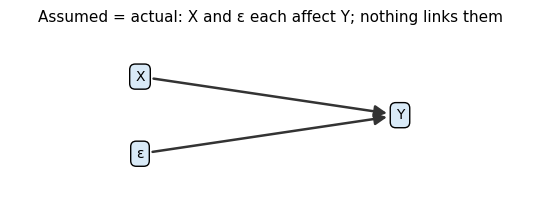

In [2]:
draw_dag([("X", "Y"), ("ε", "Y")], {"X": (0, 0.5), "ε": (0, -0.5), "Y": (2, 0)},
         "Assumed = actual: X and ε each affect Y; nothing links them", figsize=(5.5, 2.2))

In [3]:
num = 10000
np.random.seed(0)
X = np.random.normal(0, 5, num)
epsilon = np.random.normal(0, 5, num)
Y = 2 * X + epsilon
df = pd.DataFrame({"X": X, "Y": Y})
results = sm.OLS(Y, sm.add_constant(df[["X"]])).fit()
results.params["X"], results.bse["X"]

(np.float64(1.9921975243470915), np.float64(0.010056376877900404))

**Where does `bse` come from?** For one regressor:

$$SE(\hat\beta_1) = \sqrt{\frac{\hat\sigma^2}{\sum_i (X_i - \bar X)^2}}, \qquad \hat\sigma^2 = \frac{\sum_i e_i^2}{n - 2}$$

- $\hat\sigma^2$: one pooled estimate of the noise, from the residuals $e_i$ (divide by $n - 2$: two coefficients were fitted)
- $\sum_i (X_i - \bar X)^2$: how spread out X is
- More noise → bigger SE; more spread in X or more rows → smaller SE

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">WORKED BY HAND</b> &nbsp;—&nbsp; compute the SE from the formula; compare with <code>results.bse</code>
</div>

In [4]:
y_pred = results.predict(sm.add_constant(df[["X"]]))
resid = Y - y_pred

var = np.sum(resid**2) / (num - 2)       # sigma_hat squared: pooled noise
den = np.sum((X - np.mean(X))**2)        # spread of X
se = np.sqrt(var / den)

print("SE by hand:          ", se)
print("statsmodels SE for X:", results.bse["X"])

SE by hand:           0.01005637687790042
statsmodels SE for X: 0.010056376877900404


**Now check it:** rerun the study 500 times, keep each X coefficient and its reported SE.

In [5]:
def baseline_data(num=10000):
    X = np.random.normal(0, 5, num)
    epsilon = np.random.normal(0, 5, num)
    Y = 2 * X + epsilon
    return Y, pd.DataFrame({"X": X})


baseline_sims = repeat_regression(baseline_data)
summarize(baseline_sims).to_frame("baseline").T

,true beta,mean beta_hat,empirical SD,mean OLS SE,ratio
baseline,2.0,1.99998,0.01032,0.01,0.96854


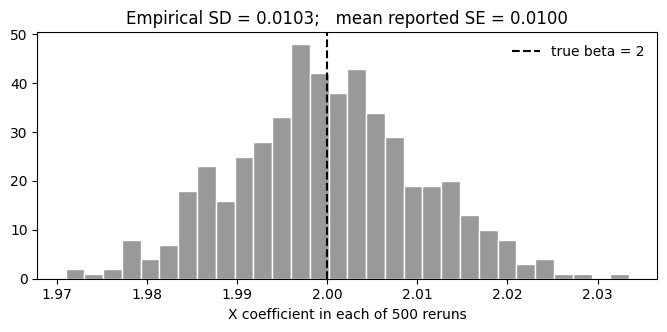

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(baseline_sims["beta_hat"], bins=30, color=GREY, edgecolor="white")
ax.axvline(2, color="black", ls="--", label="true beta = 2")
ax.set_xlabel("X coefficient in each of 500 reruns")
ax.set_title(f"Empirical SD = {baseline_sims['beta_hat'].std():.4f};   "
             f"mean reported SE = {baseline_sims['ols_se'].mean():.4f}")
ax.legend(frameon=False)
plt.show()

**Takeaway**

- The empirical SD across reruns is our benchmark: only a simulation can compute it
- The reported SE estimates that SD **from one dataset**, assuming ε is well behaved
- Here they agree (ratio ≈ 1), and the coefficient is centered on 2 → A ✓, B ✓

---
## Part 2: Omitting a confounder changes the error (8 min)

A campus coffee cart:

- **X** = flyers handed out that morning
- **Y** = cups of coffee sold
- **W** = rainfall: fewer flyers get handed out **and** fewer people buy coffee

True process (we write it, so we know it):

$$X = 80 - 25\,W + \text{flyer noise}$$

$$Y = 40 + 2\,X - 8\,W + \varepsilon$$

- Each flyer adds **2** cups; $\varepsilon$ (`err_standard_normal`) is independent noise

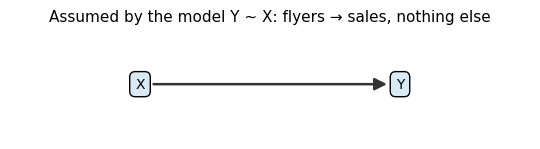

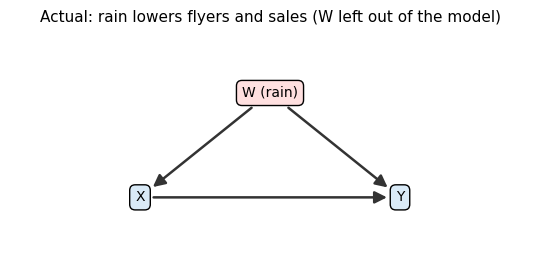

In [7]:
draw_dag([("X", "Y")], {"X": (0, 0), "Y": (2, 0)},
         "Assumed by the model Y ~ X: flyers → sales, nothing else", figsize=(5.5, 1.6))
draw_dag([("W (rain)", "X"), ("W (rain)", "Y"), ("X", "Y")],
         {"W (rain)": (1, 1), "X": (0, 0), "Y": (2, 0)},
         "Actual: rain lowers flyers and sales (W left out of the model)", red=("W (rain)",))

In [8]:
np.random.seed(42)
n_days = 300
intercept, beta, alpha = 40, 2.0, -8.0

W = np.random.gamma(shape=2.0, scale=0.4, size=n_days)       # rainfall in inches
flyer_noise = np.random.normal(loc=0, scale=5, size=n_days)
X = np.clip(80 - 25 * W + flyer_noise, 0, None)              # flyers can't be negative
err_standard_normal = np.random.normal(loc=0, scale=1, size=n_days)
Y = intercept + beta * X + alpha * W + err_standard_normal

model_1 = sm.OLS(Y, sm.add_constant(pd.DataFrame({"X": X, "W": W}))).fit()   # Y ~ X + W
model_2 = sm.OLS(Y, sm.add_constant(pd.DataFrame({"X": X}))).fit()           # Y ~ X

**Discussion:** we fit $Y \sim X$ and leave rain out. Will the flyer coefficient be above or below 2?

- On rainy days, are there more or fewer flyers?
- On rainy days, are sales higher or lower?
- So on low-flyer days, sales are low **for two reasons**. Which one gets credited to flyers?

<details><summary><b>Answer</b></summary>

- Rain → fewer flyers; rain → lower sales
- Low-flyer days are mostly rainy days, so sales are low because of fewer flyers **and** because of rain
- $Y \sim X$ can't separate the two, so it credits rain's effect to flyers → coefficient **above 2** (about 2.28)

</details>

In [9]:
pd.DataFrame({
    "X coefficient": [beta, model_1.params["X"], model_2.params["X"]],
    "reported SE": [np.nan, model_1.bse["X"], model_2.bse["X"]],
}, index=["true (structural)", "Y ~ X + W", "Y ~ X  (rain omitted)"])

,X coefficient,reported SE
true (structural),2.00000,NaN
Y ~ X + W,1.99965,0.01156
Y ~ X (rain omitted),2.28339,0.00725


- Rain omitted: the estimate is off by about 0.28, yet the reported SE is under 0.01
- **A small SE does not protect you from bias**: it measures spread, not whether the center is right

**Where did rain go?** Write the omitted model with its own error:

$$Y = 40 + 2\,X + u, \qquad u = \alpha\,W + \varepsilon = -8\,W + \varepsilon$$

- $u$ is `err_only_X` in the code
- Rain is now inside the error, and rain also moves X → **this error is correlated with X**

Three things to compare against X:

- $\varepsilon$ (`err_standard_normal`): the true error of the full model
- $u$ (`err_only_X`): the error of the model that omits $W$ (rain inside)
- $e$ (`model_2.resid`): the fitted residual from $Y \sim X$, the only one we'd see in real data

**How big is the bias?** A rough version first: rain mostly sets the number of flyers.

- Ignore flyer noise: $X \approx 80 - 25\,W$, so $W \approx \dfrac{80 - X}{25}$
- Substitute into $Y$:

$$Y \approx 40 + 2\,X - 8 \cdot \frac{80 - X}{25} + \varepsilon = \text{const} + \left(2 + \tfrac{8}{25}\right) X + \varepsilon$$

- Each extra flyer also signals $\tfrac{1}{25}$ inch less rain, worth $\tfrac{8}{25}$ cups → slope about $2.32$

In [10]:
2 + 8/25

2.32

- The fit gave about 2.28, a bit less: flyer noise means X doesn't pin down rain exactly, so X carries less information about rain
- The omitted-variable bias formula accounts for that: $\;\beta + \alpha \cdot \dfrac{\mathrm{Cov}(X, W)}{\mathrm{Var}(X)}$

In [11]:
beta + alpha * np.cov(X, W)[0, 1] / np.var(X, ddof=1)

np.float64(2.2865805363954346)

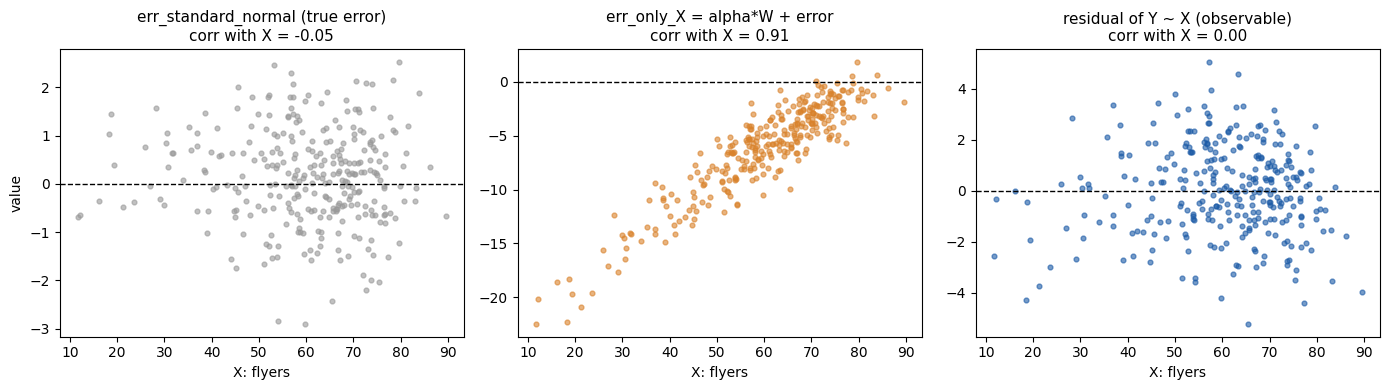

In [10]:
err_only_X = Y - intercept - beta * X        # = alpha * W + err_standard_normal

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, vals, name, color in [
    (axes[0], err_standard_normal, "err_standard_normal (true error)", GREY),
    (axes[1], err_only_X, "err_only_X = alpha*W + error", ORANGE),
    (axes[2], model_2.resid, "residual of Y ~ X (observable)", BLUE),
]:
    ax.scatter(X, vals, s=12, alpha=0.6, color=color)
    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set_title(f"{name}\ncorr with X = {np.corrcoef(X, vals)[0, 1]:.2f}", fontsize=11)
    ax.set_xlabel("X: flyers")
axes[0].set_ylabel("value")
plt.tight_layout()
plt.show()

**Why is the residual's correlation exactly 0?**

- OLS chooses the line so that residuals are uncorrelated with every regressor (with an intercept)
- So the residual plot **can't** reveal the omitted confounder
- The problem lives in the unobserved error, not in the residuals → only causal reasoning (the DAG) finds it

**Takeaway**

- Leaving out a cause of Y that also moves X puts it in the error → error correlated with X → biased coefficient
- The reported SE stays small: it describes the spread around the **wrong** center → A ✗

---
## Part 3: Heteroskedasticity — right center, wrong SE (13 min)

- Back to $Y = 2X + \varepsilon$; change **one** line: the spread of $\varepsilon$
- $\varepsilon_i \sim \mathcal{N}(0,\, X_i^2)$, i.e. $SD(\varepsilon_i \mid X_i) = |X_i|$ (code: `np.random.normal(0, np.abs(X), num)`)

**A. The mechanism**

**Discussion:** look at the ε line.

- For a given X, what is the **average** of ε? (first argument of `normal`)
- For a given X, what is its **spread**? (second argument)
- Which of those two matters for whether the coefficient is centered on 2?

<details><summary><b>Answer</b></summary>

- Average: 0 at every X
- Spread: $|X|$, so it changes with X
- The **average** decides the center: $E[\varepsilon \mid X] = 0$, so the coefficient is still centered on 2. The spread only affects the SE

</details>

X coefficient: 1.9788   reported SE: 0.0099


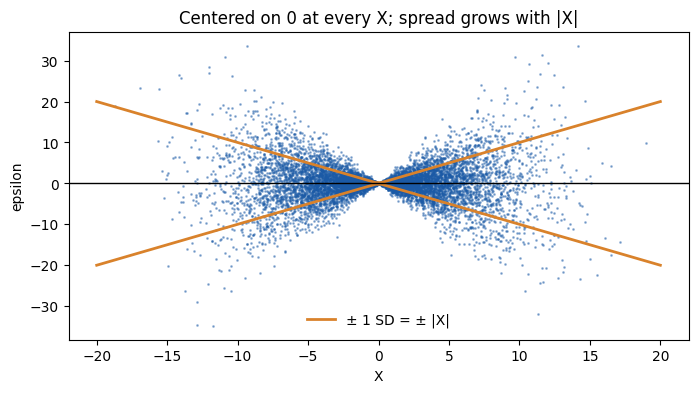

In [11]:
num = 10000
np.random.seed(0)
X = np.random.normal(0, 5, num)
epsilon = np.random.normal(0, np.abs(X), num)
Y = 2 * X + epsilon
df = pd.DataFrame({"X": X, "Y": Y})
results = sm.OLS(Y, sm.add_constant(df[["X"]])).fit()
print("X coefficient:", round(results.params["X"], 4), "  reported SE:", round(results.bse["X"], 4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(X, epsilon, ".", ms=2, alpha=0.4, color=BLUE)
xs = np.linspace(-20, 20, 100)
ax.plot(xs, np.abs(xs), color=ORANGE, lw=2, label="± 1 SD = ± |X|")
ax.plot(xs, -np.abs(xs), color=ORANGE, lw=2)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("X")
ax.set_ylabel("epsilon")
ax.set_title("Centered on 0 at every X; spread grows with |X|")
ax.legend(frameon=False)
plt.show()

In [12]:
np.corrcoef(X, epsilon)[0, 1]    # correlation between X and the errors

np.float64(-0.021374031569377692)

- Correlation ≈ 0, yet ε clearly depends on X through its **spread** → zero correlation ≠ no relationship
- The cloud is centered on 0 **because the mean argument is 0 for every X**, not because X averages 0
- $E[\varepsilon \mid X] = 0$ → no bias (question A)
- $SD(\varepsilon \mid X) = |X|$ → not constant (question B?)
- The DAG is unchanged from Part 1: this is not a causal-structure problem

**B. Compare the uncertainty measures**

**Discussion:** the conventional SE uses one pooled noise level for all rows.

- Will the coefficient still average 2?
- Will the reported SE be too small, about right, or too large?

<details><summary><b>Answer</b></summary>

- Yes, it still averages 2
- **Too small** here (ratio about 0.56): the noisiest rows are the ones far from $\bar X$, which move the slope most, but the formula treats every row as equally noisy

</details>

In [13]:
def hetero_up_data(num=10000):
    X = np.random.normal(0, 5, num)
    epsilon = np.random.normal(0, np.abs(X), num)
    Y = 2 * X + epsilon
    return Y, pd.DataFrame({"X": X})


hetero_table = pd.DataFrame({
    "homoskedastic (baseline)": summarize(repeat_regression(baseline_data)),
    "noise grows with |X|": summarize(repeat_regression(hetero_up_data)),
}).T
hetero_table

,true beta,mean beta_hat,empirical SD,mean OLS SE,ratio
homoskedastic (baseline),2.0,1.99998,0.01032,0.01,0.96854
noise grows with |X|,2.0,2.00012,0.01772,0.01,0.56413


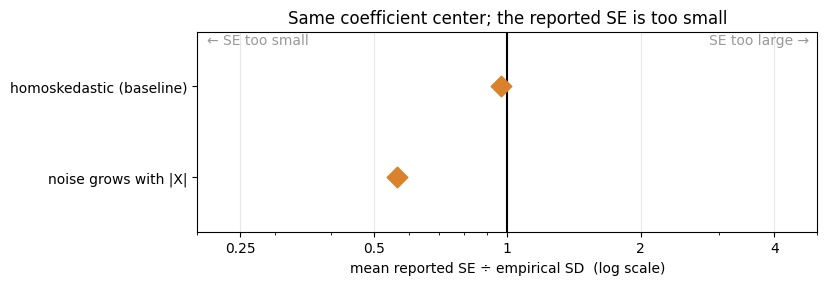

In [14]:
plot_se_ratio(hetero_table, "Same coefficient center; the reported SE is too small")

- Coefficient still averages 2 → mean zero at every X is about **bias**
- Reported SE is too small (ratio < 1) → it's about **spread**, and the formula's assumption failed

**C. Why too small here? Leverage**

- $\hat\beta_1 - \beta_1 = \dfrac{\sum_i (X_i - \bar X)\,\varepsilon_i}{\sum_i (X_i - \bar X)^2}$

<div style="background:#FFF4E0; border-left:8px solid #D9822B; padding:12px 16px; margin:8px 0; font-size:1.25em;">
✏️ <b style="color:#D9822B;">WORKED BY HAND</b> &nbsp;—&nbsp; plain vs leverage-weighted noise → predicted SE ratio
</div>

In [15]:
# rough calculation of the SE ratio when the variance of epsilon grows with X
noise_var = X**2                          # Var(eps | X) when SD = |X|

# points far from the mean of X have more leverage on the slope
leverage = (X - np.mean(X))**2

# actual: noise variance averaged with leverage as weights
true_var_scale = np.sum(noise_var * leverage) / np.sum(leverage)

# OLS assumes one constant variance: a plain average
ols_var_scale = np.mean(noise_var)

# these are variances; take the square root to compare SEs
ratio_se = np.sqrt(ols_var_scale / true_var_scale)
print("predicted ratio (OLS SE / SD):", round(ratio_se, 2))
print("simulated ratio (OLS SE / SD):", round(hetero_table.loc["noise grows with |X|", "ratio"], 2))

predicted ratio (OLS SE / SD): 0.58
simulated ratio (OLS SE / SD): 0.56


**Takeaway**

- Heteroskedasticity alone: coefficient still centered (A ✓); conventional SE can be off (B ✗)
- The direction depends on **where** the noise sits: on high-leverage rows (as here) → SE too small; on low-leverage rows → SE too large

---
## Part 4: Errors correlated across observations (4 min)

- Each error carries over part of the previous one ($\rho$ = `corr_const`, $\eta_t$ = fresh noise):

$$\varepsilon_t = \rho\,\varepsilon_{t-1} + \sqrt{1 - \rho^2}\;\eta_t, \qquad \eta_t \sim \mathcal{N}(0,\, 5^2)$$

- The $\sqrt{1 - \rho^2}$ keeps the overall spread of the errors the same (SD 5) for every $\rho$

**Discussion:** each error is still unrelated to X, so $E[\varepsilon \mid X] = 0$ still holds.

- Is the coefficient biased?
- 100 rows where each looks like its neighbor: is that 100 independent pieces of information?
- So will the reported SE be too small or too large?

<details><summary><b>Answer</b></summary>

- Not biased: each error is still unrelated to X, so the coefficient stays centered on 2
- No: neighbouring rows repeat much of the same information, so there are effectively fewer independent observations
- **Too small**, and more so as $\rho$ grows (ratio about 0.98 → 0.79 → 0.34)

</details>

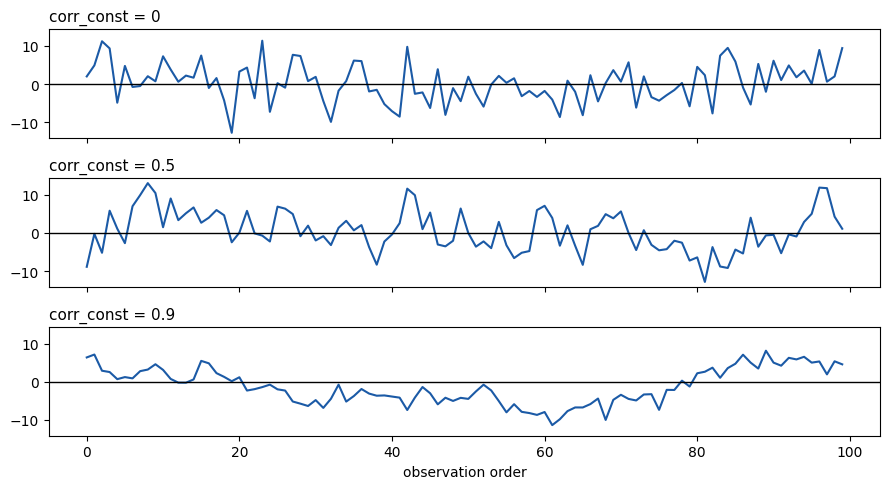

In [16]:
def make_error(corr_const, num):
  err = list()
  prev = np.random.normal(0, 5)
  for n in range(num):
    prev = corr_const * prev + np.sqrt(1 - corr_const**2) * np.random.normal(0, 5)
    err.append(prev)
  return np.array(err)


np.random.seed(0)
fig, axes = plt.subplots(3, 1, figsize=(9, 5), sharex=True, sharey=True)
for ax, c in zip(axes, [0, 0.5, 0.9]):
    ax.plot(make_error(c, 100), color=BLUE)
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"corr_const = {c}", fontsize=11, loc="left")
axes[-1].set_xlabel("observation order")
plt.tight_layout()
plt.show()

- X and ε are both built with `make_error`: X also drifts over time, not only ε

In [17]:
def serial_data(corr_const, num=100):
    X = make_error(corr_const, num)
    Y = 2 * X + make_error(corr_const, num)
    return Y, pd.DataFrame({"X": X})


serial_table = pd.DataFrame({
    f"corr_const = {c}": summarize(repeat_regression(lambda: serial_data(c)))
    for c in [0, 0.5, 0.9]
}).T
serial_table

,true beta,mean beta_hat,empirical SD,mean OLS SE,ratio
corr_const = 0,2.0,2.00062,0.10308,0.10123,0.98208
corr_const = 0.5,2.0,2.00230,0.12853,0.10128,0.78797
corr_const = 0.9,2.0,2.01825,0.29371,0.10099,0.34384


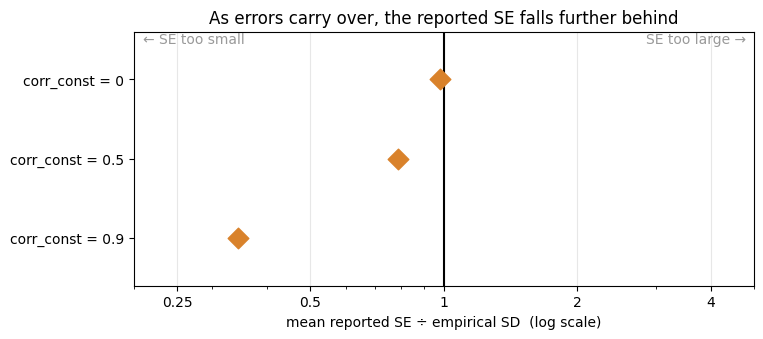

In [18]:
plot_se_ratio(serial_table, "As errors carry over, the reported SE falls further behind")

**Takeaway**

- Coefficient still centered on 2 (A ✓); reported SE increasingly too small (B ✗)
- **Error correlated with X** (Part 2) ≠ **errors correlated with each other** (Part 4)
    - Part 2 breaks the coefficient
    - Part 4 breaks the SE
- The size of the gap depends on X drifting too: if X were shuffled independently, the damage would be much smaller

**Putting it together** (each row assumes the other assumptions hold)

| What's wrong with ε | What primarily goes wrong? |
|---|---|
| Omitted confounder → correlated with X | Coefficient can target the wrong effect |
| Heteroskedasticity | Conventional SE can be too small **or** too large |
| Correlated across observations | Conventional SE can misstate uncertainty |